<a href="https://colab.research.google.com/github/amrkamel2252004-boop/hi/blob/main/relative-elevation-model/rem-in-xarray-tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial: Relative Elevation Model: Mississippi River

- Credit: [Dahn](https://twitter.com/DahnJahn)

# Step 0: Setup

### Imports

In [24]:
!pip install osmnx scipy xarray rioxarray matplotlib datashader xarray-spatial

In [ ]:
import os
# إعادة تشغيل جلسة العمل برمجياً لتحديث مكتبات نظام التشغيل والـ Python
os.kill(os.getpid(), 9)

In [ ]:
pip install xarray-spatial -q

In [ ]:
from pathlib import Path
from IPython.core.display import Video

import numpy as np
import pandas as pd
import geopandas as gpd  # Vector data handling
import osmnx as ox       # Downloading data from OSM

from shapely.geometry import box
from scipy.spatial import cKDTree as KDTree # For Inverse Distance Weight calculation

import xarray as xr
import xrspatial    # Hillshading
import rioxarray    # Working with geospatial data in xarray

import matplotlib.pyplot as plt
from datashader.transfer_functions import shade, stack

### تعديل الكود لنهر النيل (Nile River)
هنا سنقوم بتعريف إحداثيات مضلع جديد يمر عبره نهر النيل في مصر (على سبيل المثال منطقة قريبة من الأقصر/قنا)، بالإضافة إلى جلب بيانات نهر النيل باستخدام `osmnx`.

In [3]:
!pip install osmnx -q

In [4]:
# 1. استيراد المكتبة
import osmnx as ox

# 2. تحديد منطقة الدراسة حول نهر النيل
nile_geom = '''{
  "type": "Polygon",
  "coordinates": [[
    [32.4, 25.5],
    [33.0, 25.5],
    [33.0, 26.2],
    [32.4, 26.2],
    [32.4, 25.5]
  ]]
}'''

# 3. جلب مسار نهر النيل من OpenStreetMap
try:
    nile_river = ox.geocode_to_gdf('Nile River', which_result=1)
    print("تم تحميل بيانات نهر النيل بنجاح!")
    display(nile_river.head())
except Exception as e:
    print(f"حدث خطأ أثناء تحميل البيانات: {e}")

تم تحميل بيانات نهر النيل بنجاح!


,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,"MULTILINESTRING ((32.90925 16.52626, 32.91658 ...",30.28892,15.641242,33.987719,31.526457,44769455,relation,50793,22.724378,32.105331,waterway,river,18,0.674503,river,Nile River,"Nile River, Egypt"


### تحميل بيانات الارتفاع الرقمي (DEM) لنهر النيل في مصر
سنقوم باستخدام مكتبة `elevation` أو تنزيل ملف SRTM DEM المناسب لإحداثيات نهر النيل في مصر مباشرة من الروابط العامة أو باستخدام مكتبة `rioxarray` لقراءة رابط مرجعي.

In [5]:
# تثبيت مكتبات إضافية إذا لزم الأمر لتحميل الـ DEM
!pip install elevation -q

In [11]:
!pip install rioxarray geojson xarray-spatial -q

In [6]:
# سنقوم بتحميل الـ DEM للمنطقة المحددة حول الأقصر وقنا
import os
import elevation

dem_path = 'nile_dem.tif'

# تحديد حدود المنطقة [xmin, ymin, xmax, ymax]
# 32.4, 25.5, 33.0, 26.2
try:
    elevation.clip(bounds=(32.4, 25.5, 33.0, 26.2), output=dem_path)
    print("تم تحميل ملف DEM الخاص بنهر النيل بنجاح!")
except Exception as e:
    print(f"حدث خطأ أثناء تحميل DEM: {e}"
          "\nيمكنك أيضاً رفع ملف DEM الخاص بك يدوياً وتسميته nile_dem.tif")

تم تحميل ملف DEM الخاص بنهر النيل بنجاح!


## Step 1: Download & Load DEM

- [USGS LidarExplorer](https://prd-tnm.s3.amazonaws.com/LidarExplorer/index.html#/)

#### **VIDEO**: How to download data from NLS

The downloaded data can be combined using the convenience function[`combine_by_coords`](https://xarray.pydata.org/en/stable/generated/xarray.combine_by_coords.html#xarray.combine_by_coords).

In [12]:
# تحميل الـ DEM الخاص بنهر النيل وإعادة تعريفه بترميز إحداثيات WGS84 (EPSG:4326)
import rioxarray
dem = rioxarray.open_rasterio('nile_dem.tif')
dem = dem.rio.write_crs(4326)
print("تم تحميل وقراءة ملف الـ DEM لنهر النيل بنجاح!")

تم تحميل وقراءة ملف الـ DEM لنهر النيل بنجاح!


Make DEM smaller and clip to focus area

In [ ]:
import geojson

In [8]:
# مضلع القص الخاص بنهر النيل في مصر
geom = nile_geom

In [13]:
import geojson
cropping_geometries = [geojson.loads(geom)]
# قص بيانات الارتفاع الرقمي (DEM) بناءً على إحداثيات مضلع نهر النيل المختار
cropped = dem.rio.clip(geometries=cropping_geometries, crs=4326)

In [ ]:
cropped = cropped.coarsen(x=3, boundary='trim').mean().coarsen(y=3, boundary='trim').mean()

Let's plot the DEM

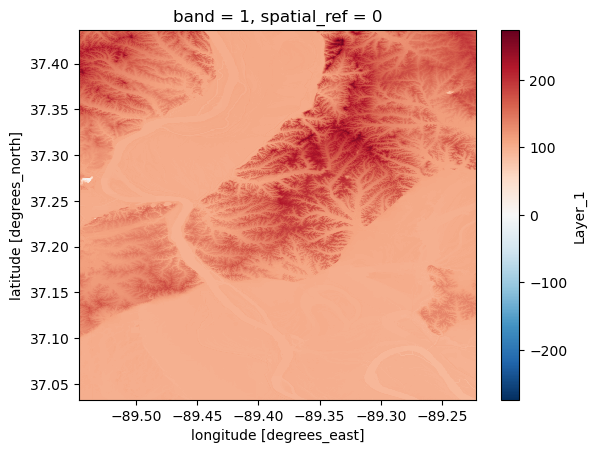

In [ ]:
cropped.squeeze().plot.imshow()

## Step 2: Fetch coordinates of the river

In [14]:
# تأكيد تعريف cropped المقلص أولاً ثم تحويل نظام الإحداثيات لمتجه نهر النيل
import rioxarray
dem = rioxarray.open_rasterio('nile_dem.tif')
dem = dem.rio.write_crs(4326)

import geojson
cropping_geometries = [geojson.loads(nile_geom)]
cropped = dem.rio.clip(geometries=cropping_geometries, crs=4326)
cropped = cropped.coarsen(x=3, boundary='trim').mean().coarsen(y=3, boundary='trim').mean()

river = nile_river.to_crs(cropped.rio.crs)

Let's plot the river

<Axes: >

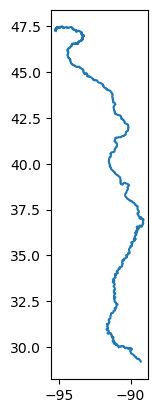

In [ ]:
river.plot()

## Step 3: Cut to area of interest

#### River

In [15]:
# جلب حدود ملف الـ DEM المقصوص جغرافياً لنهر النيل
cropped.rio.bounds()

(32.40013888888889, 25.500416666666666, 32.99958333333335, 26.199861111111108)

In [ ]:
bounds = cropped.rio.bounds()
xmin, ymin, xmax, ymax = bounds

In [ ]:
river = river.clip(bounds)

/tmp/ipykernel_1985/652125327.py:7: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  intersection = river.geometry.unary_union.intersection(study_area_box)


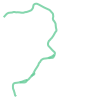

In [18]:
# استخراج الجزء الفعلي من مجرى نهر النيل الذي يقع داخل منطقة الدراسة وتجنب أي خطوط خارجية
from shapely.geometry import box

# الحصول على الحدود مباشرة
xmin, ymin, xmax, ymax = cropped.rio.bounds()
study_area_box = box(xmin, ymin, xmax, ymax)
intersection = river.geometry.unary_union.intersection(study_area_box)

# الاحتفاظ بالجزء الأكبر أو المتقاطع كمجرى النهر الرئيسي للمحاكاة
river_geom = intersection
river_geom

#### DEM

In [ ]:
cropped = cropped.sel(y=slice(ymax, ymin), x=slice(xmin, xmax))

Let's check if everything looks good

<Axes: title={'center': 'band = 1, spatial_ref = 0'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

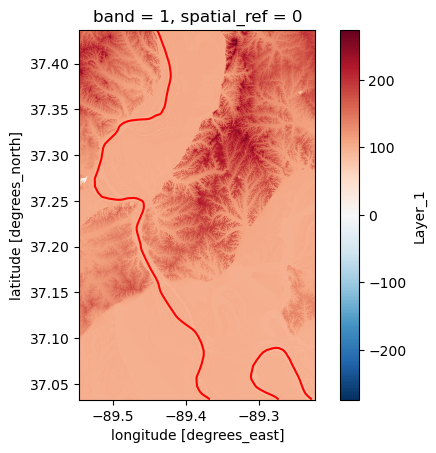

In [ ]:
fig, ax = plt.subplots()
cropped.squeeze().plot.imshow(ax=ax)
river.plot(ax=ax, color='red')

## Step 4: Calculate REM

To calculate the REM, we need to
1. Sample the elevation along the river
2. Interpolate the sampled elevation values to create a 2D elevation raster
3. Subtract the interpolated elevation raster from the DEM

### 4.1. Sample

Extract coordinates as `DataArray`

In [ ]:
import shapely

def split_coords(geom):
    x = []
    y = []
    for i in shapely.get_coordinates(geom):
        x.append(i[0])
        y.append(i[1])
    return x, y


In [ ]:
xs, ys = split_coords(river_geom)
xs, ys = xr.DataArray(xs, dims='z'), xr.DataArray(ys, dims='z')

Use xarray's [`interp`](https://xarray.pydata.org/en/stable/generated/xarray.DataArray.interp.html#xarray.DataArray.interp) to extract the river's elevation.

In [ ]:
sampled = cropped.interp(x=xs, y=ys, method='nearest').dropna(dim='z')

### 4.2. Interpolate

Prepare data for the interpolation

In [ ]:
# Sampled river coordinates
c_sampled = np.vstack([sampled.coords[c].values for c in ('x', 'y')]).T

# All (x, y) coordinates of the original DEM
c_x, c_y = [cropped.coords[c].values for c in ('x', 'y')]
c_interpolate = np.dstack(np.meshgrid(c_x, c_y)).reshape(-1, 2)

# Sampled values
values = sampled.values.ravel()

In [ ]:
c_interpolate

array([[-89.54625   ,  37.43652778],
       [-89.54597222,  37.43652778],
       [-89.54569444,  37.43652778],
       ...,
       [-89.22291667,  37.03291667],
       [-89.22263889,  37.03291667],
       [-89.22236111,  37.03291667]])

Perform the interpolation. Here we use a simple implementation of [IWD](https://en.wikipedia.org/wiki/Inverse_distance_weighting) which averages the 5 nearest points, weighted by inverse distance.

In [ ]:
tree

In [ ]:
tree = KDTree(c_sampled)

In [ ]:
# IWD interpolation
distances, indices = tree.query(c_interpolate, k=50)

weights = 1 / distances
weights = weights / weights.sum(axis=1).reshape(-1, 1)

interpolated_values = (weights * values[indices]).sum(axis=1)

In [ ]:
interpolated_values

array([98.31997252, 98.32033693, 98.32070347, ..., 90.30985072,
       90.3143536 , 90.3187768 ])

We create a `DataArray` out of the inerpolated values

In [ ]:
elevation_raster = xr.DataArray(
    interpolated_values.reshape((len(c_y), len(c_x))).T, dims=('x', 'y'), coords={'x': c_x, 'y': c_y}
)

<Axes: xlabel='x', ylabel='y'>

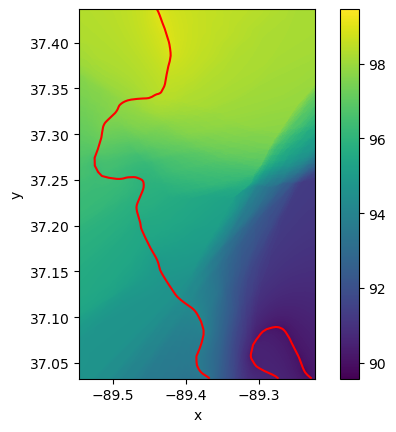

In [ ]:
fig, ax = plt.subplots()
elevation_raster.transpose().plot.imshow(ax=ax)
river.plot(ax=ax, color='red')

### 4.3. Calculate

In [ ]:
rem = cropped - elevation_raster

# Step 5: Visualize

Let's make some pretty REM visualizations!

In [ ]:
colors = ['#f2f7fb', '#81a8cb', '#37123d']

/tmp/ipykernel_4479/1630365594.py:36: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  river_geom = river.geometry.unary_union.intersection(study_area_box)


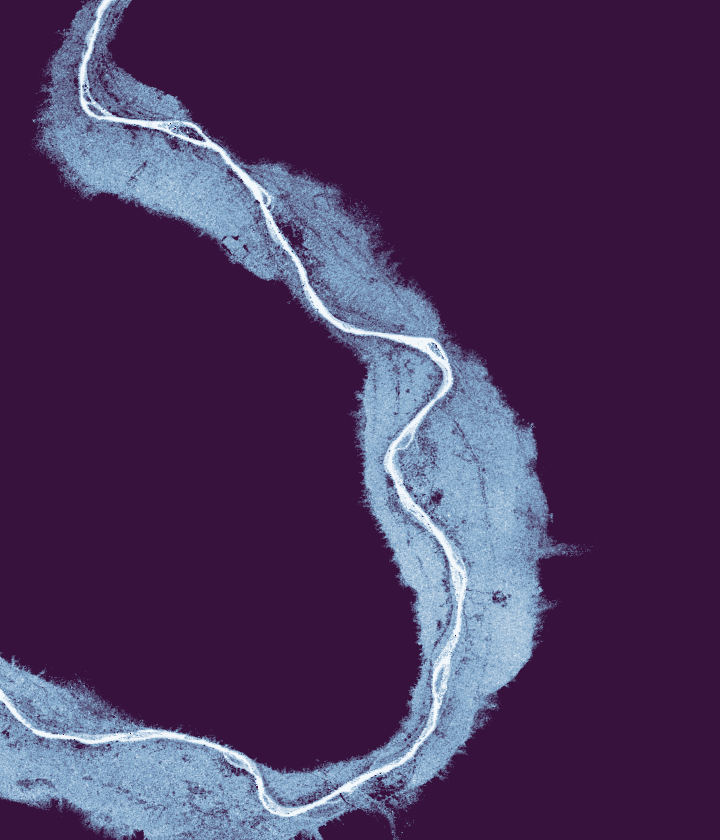

In [5]:
import rioxarray
import geojson
import numpy as np
import xarray as xr
import xrspatial
import osmnx as ox
from scipy.spatial import cKDTree as KDTree
from datashader.transfer_functions import shade, stack

# 1. تعريف مضلع الدراسة لنهر النيل بعد إعادة تشغيل الجلسة
nile_geom = '''{
  "type": "Polygon",
  "coordinates": [[
    [32.4, 25.5],
    [33.0, 25.5],
    [33.0, 26.2],
    [32.4, 26.2],
    [32.4, 25.5]
  ]]
}'''

# جلب بيانات نهر النيل
nile_river = ox.geocode_to_gdf('Nile River', which_result=1)

# 2. تحميل الـ DEM للمنطقة المحددة حول الأقصر وقنا
dem = rioxarray.open_rasterio('nile_dem.tif').rio.write_crs(4326)
cropping_geometries = [geojson.loads(nile_geom)]
cropped = dem.rio.clip(geometries=cropping_geometries, crs=4326)
cropped = cropped.coarsen(x=3, boundary='trim').mean().coarsen(y=3, boundary='trim').mean()

# 3. استخراج مسار نهر النيل
river = nile_river.to_crs(cropped.rio.crs)
xmin, ymin, xmax, ymax = cropped.rio.bounds()
from shapely.geometry import box
study_area_box = box(xmin, ymin, xmax, ymax)
river_geom = river.geometry.unary_union.intersection(study_area_box)

# 4. حساب الارتفاع المأخوذ
import shapely
def split_coords(geom):
    x = []
    y = []
    for i in shapely.get_coordinates(geom):
        x.append(i[0])
        y.append(i[1])
    return x, y

xs, ys = split_coords(river_geom)
xs, ys = xr.DataArray(xs, dims='z'), xr.DataArray(ys, dims='z')
sampled = cropped.interp(x=xs, y=ys, method='nearest').dropna(dim='z')

# 5. الاستيفاء (Interpolation)
c_sampled = np.vstack([sampled.coords[c].values for c in ('x', 'y')]).T
c_x, c_y = [cropped.coords[c].values for c in ('x', 'y')]
c_interpolate = np.dstack(np.meshgrid(c_x, c_y)).reshape(-1, 2)
values = sampled.values.ravel()

tree = KDTree(c_sampled)
distances, indices = tree.query(c_interpolate, k=50)
weights = 1 / distances
weights = weights / weights.sum(axis=1).reshape(-1, 1)
interpolated_values = (weights * values[indices]).sum(axis=1)

elevation_raster = xr.DataArray(
    interpolated_values.reshape((len(c_y), len(c_x))).T, dims=('x', 'y'), coords={'x': c_x, 'y': c_y}
)

# 6. حساب الارتفاع النسبي (REM)
rem = cropped - elevation_raster

# 7. رسم وتلوين الـ REM
colors = ['#f2f7fb', '#81a8cb', '#37123d']
shade(rem.squeeze(), cmap=colors, span=[0, 15], how='linear')

![](https://i.imgur.com/MFagpMt.jpg)

We can also visualize the DEM along with the REM

/tmp/ipykernel_4479/176502320.py:36: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  river_geom = river.geometry.unary_union.intersection(study_area_box)


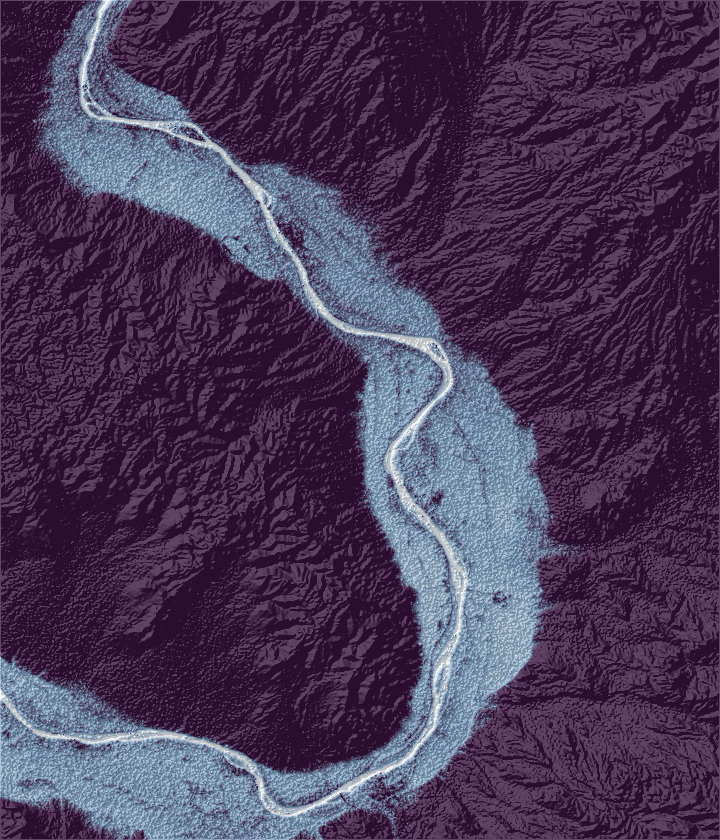

In [6]:
import rioxarray
import geojson
import numpy as np
import xarray as xr
import xrspatial
import osmnx as ox
from scipy.spatial import cKDTree as KDTree
from datashader.transfer_functions import shade, stack

# 1. تعريف مضلع الدراسة لنهر النيل
nile_geom = '''{
  "type": "Polygon",
  "coordinates": [[
    [32.4, 25.5],
    [33.0, 25.5],
    [33.0, 26.2],
    [32.4, 26.2],
    [32.4, 25.5]
  ]]
}'''

# جلب بيانات نهر النيل
nile_river = ox.geocode_to_gdf('Nile River', which_result=1)

# 2. تحميل الـ DEM المقصوص والمقلص
dem = rioxarray.open_rasterio('nile_dem.tif').rio.write_crs(4326)
cropping_geometries = [geojson.loads(nile_geom)]
cropped = dem.rio.clip(geometries=cropping_geometries, crs=4326)
cropped = cropped.coarsen(x=3, boundary='trim').mean().coarsen(y=3, boundary='trim').mean()

# 3. استخراج مسار نهر النيل وتقاطعه مع منطقة الدراسة
river = nile_river.to_crs(cropped.rio.crs)
xmin, ymin, xmax, ymax = cropped.rio.bounds()
from shapely.geometry import box
study_area_box = box(xmin, ymin, xmax, ymax)
river_geom = river.geometry.unary_union.intersection(study_area_box)

# 4. حساب نقاط الارتفاع على مجرى النهر
import shapely
def split_coords(geom):
    x, y = [], []
    for i in shapely.get_coordinates(geom):
        x.append(i[0])
        y.append(i[1])
    return x, y

xs, ys = split_coords(river_geom)
xs, ys = xr.DataArray(xs, dims='z'), xr.DataArray(ys, dims='z')
sampled = cropped.interp(x=xs, y=ys, method='nearest').dropna(dim='z')

# 5. الاستيفاء (Interpolation)
c_sampled = np.vstack([sampled.coords[c].values for c in ('x', 'y')]).T
c_x, c_y = [cropped.coords[c].values for c in ('x', 'y')]
c_interpolate = np.dstack(np.meshgrid(c_x, c_y)).reshape(-1, 2)
values = sampled.values.ravel()

tree = KDTree(c_sampled)
distances, indices = tree.query(c_interpolate, k=50)
weights = 1 / distances
weights = weights / weights.sum(axis=1).reshape(-1, 1)
interpolated_values = (weights * values[indices]).sum(axis=1)

elevation_raster = xr.DataArray(
    interpolated_values.reshape((len(c_y), len(c_x))).T, dims=('x', 'y'), coords={'x': c_x, 'y': c_y}
)

# 6. حساب الارتفاع النسبي
rem = cropped - elevation_raster
colors = ['#f2f7fb', '#81a8cb', '#37123d']

# 7. دمج التظليل الأرضي الـ Hillshade مع نموذج الـ REM لنهر النيل بشكل مجسم
a = shade(xrspatial.hillshade(cropped.squeeze(), angle_altitude=1, azimuth=310), cmap=['black', 'white'], how='linear')
b = shade(rem.squeeze(), cmap=colors, span=[0, 15], how='linear', alpha=200)
stack(a, b)

In [7]:
# حفظ مصفوفة الارتفاع النسبي (REM) الناتجة مباشرة كملف GeoTIFF مرجعي جغرافياً
output_filename = 'nile_rem.tif'

try:
    # كتابة المصفوفة إلى ملف Raster
    rem.rio.to_raster(output_filename)
    print(f"تم حفظ خريطة الـ REM بنجاح كملف GeoTIFF باسم: {output_filename}")
except Exception as e:
    print(f"حدث خطأ أثناء حفظ الملف: {e}")

تم حفظ خريطة الـ REM بنجاح كملف GeoTIFF باسم: nile_rem.tif


In [8]:
from google.colab import files

# تحميل ملف الـ REM الجغرافي إلى جهازك المحلي
files.download('nile_rem.tif')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
!pip install rasterstats -q

In [10]:
import geopandas as gpd
from rasterstats import zonal_stats
import pandas as pd

# إنشاء مساحة عازلة (Buffer) حول خط مجرى النهر لاستخدامها كمنطقة لحساب الإحصائيات
river_gdf = gpd.GeoDataFrame(geometry=[river_geom], crs=4326)
# تحويل الإحداثيات إلى نظام متري لحساب مسافةBuffer واقعية (مثلاً 2000 متر)
river_buffered = river_gdf.to_crs(epsg=32636).buffer(2000).to_crs(epsg=4326)

# حساب الإحصائيات المناطقية لملف الـ REM
stats = zonal_stats(river_buffered, 'nile_rem.tif', stats=['min', 'max', 'mean', 'median', 'std'])

# عرض النتائج في جدول
df_stats = pd.DataFrame(stats)
df_stats.columns = ['الحد الأدنى (Min)', 'الحد الأقصى (Max)', 'المتوسط (Mean)', 'الوسيط (Median)', 'الانحراف المعياري (Std)']
display(df_stats)

,الحد الأدنى (Min),الحد الأقصى (Max),المتوسط (Mean),الوسيط (Median),الانحراف المعياري (Std)
0,-517.326654,931.918433,8.572687,7.063945,8.487607


![](https://i.imgur.com/jRXcHVi.jpg)